In [1]:
import os, random, operator, sys
from collections import Counter
import random
import collections
import math
import sys
from util import *

## 一些功能函数
需要阅读这些函数来对实验中用到的数据结构，步骤有一些理解

In [2]:
def dotProduct(d1, d2):
    """
    @param dict d1: a feature vector represented by a mapping from a feature (string) to a weight (float).
    @param dict d2: same as d1
    @return float: the dot product between d1 and d2
    """
    if len(d1) < len(d2):
        return dotProduct(d2, d1)
    else:
        return sum(d1.get(f, 0) * v for f, v in d2.items())


In [3]:
def increment(d1, scale, d2):
    """
    Implements d1 += scale * d2 for sparse vectors.
    @param dict d1: the feature vector which is mutated.
    @param float scale
    @param dict d2: a feature vector.
    """
    for f, v in d2.items():
        d1[f] = d1.get(f, 0) + v * scale


In [4]:
def readExamples(path):
    '''
    读取数据
    '''
    examples = []
    for line in open(path, encoding = "ISO-8859-1"):
        # Format of each line: <output label (+1 or -1)> <input sentence>
        y, x = line.split(' ', 1)
        examples.append((x.strip(), int(y)))
    print('Read %d examples from %s' % (len(examples), path))
    return examples


In [5]:
def evaluatePredictor(examples, predictor):
    '''
    在|examples|上测试|predictor|的性能，返回错误率
    '''
    error = 0
    for x, y in examples:
        if predictor(x) != y:
            error += 1
    return 1.0 * error / len(examples)

## Feature extrator (Your codes here)

### (1) 使用BOW作为特征
(a) 复习BOW
(b) 如何把一个句子（字符串）转化成BOW的特征？

In [6]:
def extractFeatures_BOW(x):
    """
    从字符串x中提取特征
    @param string x: 
    @return dict: a feature vector represented by a mapping from a feature (string) to a weight (float).
    """
    features = collections.defaultdict(float)
    words = x.split()
    for word in words:
        features[word] += 1.0
    return features

### (2) 使用N-Gram作为特征
(a) 复习N-Gram相关的内容
(b) 字级别N-Gram还是词语级别？
(c) 如何把一个句子（字符串）转化成N-Gram的特征？

In [7]:
def extractFeatures_Ngram(x, n=2):
    """
    从字符串x中提取特征
    @param string x: 
    @return dict: a feature vector represented by a mapping from a feature (string) to a weight (float).
    """
    features = collections.defaultdict(float)
    words = x.split()
    
    # 生成n-gram
    for i in range(len(words) - n + 1):
        ngram = ' '.join(words[i:i+n])
        features[ngram] += 1.0
    
    return features

### （3） 使用word2vec作为特征
(a) 获得词向量。你可以借鉴第一次的作业，使用gensim来自己训练一个word2vec, 或者加载预训练过的word2vec(gensim的网站上有说明如何下载并使用预训练过的词向量)。
(b) 考虑如何使用词向量得到句子的表示向量（feature）。
(c) 将向量转化为其余部分可以处理的形式（如：dict）
(d) 考虑如何**更好地**使用词向量得到句子的表示向量（feature）。

提示: 在ipynb的代码块中可以使用! 来执行命令行中的命令, 例如
```
!pip install gensim
```

**考虑到计算机内存限制和本实验数据量，选择100维的GloVe而不是Word2vec作为预训练词向量。**

使用genism的word2vec加载器加载预训练词向量：

In [8]:
from gensim.models import KeyedVectors
import os

# GloVe文件
glove_file = 'glove.6B.100d.txt'

# 使用word2vec加载器
word_vectors = KeyedVectors.load_word2vec_format(
    glove_file, 
    binary=False, 
    no_header=True,  # 告诉gensim：这个文件没有头部信息
    encoding='utf-8'
)

print(f"加载成功！词汇表大小：{len(word_vectors.key_to_index)}")
print(f"向量维度：{word_vectors.vector_size}")

加载成功！词汇表大小：400000
向量维度：100


In [9]:
import numpy as np

def extractFeatures_Word2Vec(x, word_vectors=word_vectors):
    """
    从字符串x中提取特征
    @param string x: 
    @param word_vectors: 预训练词向量字典，如果没有则随机初始化
    @return dict: a feature vector represented by a mapping from a feature (string) to a weight (float).
    """
    words = x.split()
    if not words:
        return {}
    
    # 收集所有在词向量中出现的词的向量
    vectors = []
    for word in words:
        if word in word_vectors:
            vectors.append(word_vectors[word])
    
    if not vectors:  # 如果没有词在词向量中
        return {}
    
    # 计算平均向量
    avg_vector = np.mean(vectors, axis=0)
    
    # 转换为特征字典格式
    features = {}
    for i, val in enumerate(avg_vector):
        features[f'dim_{i}'] = float(val)
    
    return features

In [51]:
def extractFeatures_Word2Vec_2(x, word_vectors=word_vectors):
    """
    从字符串x中提取特征
    @param string x: 
    @param word_vectors: 预训练词向量字典，如果没有则随机初始化
    @return vector: a feature vector.
    """
    words = x.split()
    if not words:
        return {}
    
    # 收集所有在词向量中出现的词的向量
    vectors = []
    for word in words:
        if word in word_vectors:
            vectors.append(word_vectors[word])
    
    if not vectors:  # 如果没有词在词向量中
        return {}
    
    # 计算平均向量
    avg_vector = np.mean(vectors, axis=0)
    
    return avg_vector

### (4) Test your feature extractor
实现了特征提取函数之后，可以简单地测试输出的正确性

In [7]:
extractFeatures_BOW("a truly wonderful tale combined with stunning animation .")

defaultdict(float,
            {'a': 1.0,
             'truly': 1.0,
             'wonderful': 1.0,
             'tale': 1.0,
             'combined': 1.0,
             'with': 1.0,
             'stunning': 1.0,
             'animation': 1.0,
             '.': 1.0})

In [41]:
extractFeatures_Ngram("a truly wonderful tale combined with stunning animation .")

defaultdict(float,
            {'a truly': 1.0,
             'truly wonderful': 1.0,
             'wonderful tale': 1.0,
             'tale combined': 1.0,
             'combined with': 1.0,
             'with stunning': 1.0,
             'stunning animation': 1.0,
             'animation .': 1.0})

In [12]:
extractFeatures_Word2Vec("a truly wonderful tale combined with stunning animation .")

{'dim_0': -0.05586777627468109,
 'dim_1': 0.36306509375572205,
 'dim_2': 0.32095974683761597,
 'dim_3': -0.12742334604263306,
 'dim_4': 0.22243690490722656,
 'dim_5': 0.21795640885829926,
 'dim_6': 0.05667588487267494,
 'dim_7': 0.1669861227273941,
 'dim_8': -0.34035444259643555,
 'dim_9': -0.018175555393099785,
 'dim_10': -0.000563889741897583,
 'dim_11': -0.18449079990386963,
 'dim_12': 0.07941921800374985,
 'dim_13': -0.20217488706111908,
 'dim_14': 0.056006450206041336,
 'dim_15': 0.16889221966266632,
 'dim_16': 0.0472104474902153,
 'dim_17': 0.06239987909793854,
 'dim_18': -0.07938199490308762,
 'dim_19': 0.44667449593544006,
 'dim_20': 0.19869934022426605,
 'dim_21': -0.11232855916023254,
 'dim_22': 0.1539251208305359,
 'dim_23': -0.09776787459850311,
 'dim_24': 0.370585560798645,
 'dim_25': 0.04413255676627159,
 'dim_26': -0.11873788386583328,
 'dim_27': 0.04766999930143356,
 'dim_28': -0.18370865285396576,
 'dim_29': -0.3881755769252777,
 'dim_30': -0.2963384687900543,
 'dim_31

## 学习与梯度更新
你需要理解题目中的loss_function, 自行推导出weights的更新公式，
通过对训练集上样本的迭代，来更新weights

#### 反向传播公式推导
把每条影评文本$x$映射为对应的特征向量$\boldsymbol{\phi}(x)$，简单线性模型的预测得分为：
$$
\begin{flalign}
&\qquad f(x)=\mathbf{w} \cdot \boldsymbol{\phi}(x) &
\end{flalign}
$$
Hinge Loss为：
$$\begin{flalign}
&\qquad L(y, f(x))=\max(0, 1 - y * f(x)) &
\end{flalign}$$
其中$y$是真实标签（$+1$或$-1$）。带入$f(x)$的公式得到：
$$
\begin{flalign}
&\qquad
\begin{aligned}
L(x, y; \mathbf{w}) 
&= \max(0, 1 - \mathbf{w} \cdot \boldsymbol{\phi}(x)y) \\
&= 
\begin{cases} 
1 - \mathbf{w} \cdot \boldsymbol{\phi}(x)y, & \text{if } \mathbf{w} \cdot \boldsymbol{\phi}(x)y < 1 \\
0, & \text{if } \mathbf{w} \cdot \boldsymbol{\phi}(x)y \geq 1
\end{cases}
\end{aligned} &
\end{flalign}
$$
反向传播需要计算损失函数对权重$\mathbf{w}$的偏导数：$\frac{\partial L}{\partial \mathbf{w}}$，
当$\mathbf{w} \cdot \boldsymbol{\phi}(x)y < 1$时：
$$\begin{flalign}
&\qquad L(x, y; \mathbf{w}) = 1 - \mathbf{w} \cdot \boldsymbol{\phi}(x)y = 1 - y \cdot \sum_{i}{\mathbf{w}_{i} \cdot \boldsymbol{\phi}_{i}(x)} &
\end{flalign}$$
对第$j$个权重$\mathbf{w}_j$求偏导：
$$\begin{flalign}
&\qquad \frac{\partial L}{\partial \mathbf{w}_j} = \frac{\partial}{\partial \mathbf{w}_j}(1 - y \cdot \sum_{i}{\mathbf{w}_{i} \cdot \boldsymbol{\phi}_{i}(x)}) = - y \cdot \boldsymbol{\phi}_{j}(x) &
\end{flalign}$$
当$\mathbf{w} \cdot \boldsymbol{\phi}(x)y \geq 1$时：$\frac{\partial L}{\partial \mathbf{w}_j} = 0$。

完整的向量形式反向传播公式为：
$$
\begin{flalign}
&\qquad \frac{\partial L}{\partial \mathbf{w}} = 
\begin{cases} 
- y \cdot \boldsymbol{\phi}(x), & \text{if } \mathbf{w} \cdot \boldsymbol{\phi}(x)y < 1 \\
0, & \text{if } \mathbf{w} \cdot \boldsymbol{\phi}(x)y \geq 1
\end{cases} &
\end{flalign}
$$

In [10]:
# 学习与梯度更新函数（使用统计特征提取）
def learnPredictor(trainExamples, testExamples, featureExtractor, numIters, eta):
    '''
    给定训练数据和测试数据，特征提取器|featureExtractor|、训练轮数|numIters|和学习率|eta|，
    返回学习后的权重weights
    你需要实现随机梯度下降优化权重
    '''
    # 初始化权重为空字典
    weights = collections.defaultdict(float)
    train_losses = []
    test_losses = []
    train_errors = []
    test_errors = []
    for  i in range(1, numIters+1):
        # 随机打乱训练数据
        random.shuffle(trainExamples)
        
        total_loss = 0.0
        
        for x, y in trainExamples:
            # 提取特征
            features = featureExtractor(x)
            
            # 计算当前预测值（w·x）            
            score = dotProduct(weights, features)            

            # 计算Hinge Loss的梯度并更新权重
            # Hinge Loss: max(0, 1 - y * (w·x))
            # 当 y * (w·x) < 1 时，梯度为 -y * x
            margin = y * score
            # 有损失，需要更新权重
            if margin < 1: 
                # 梯度下降：w = w - eta * ( -y * x ) = w + eta * y * x
                increment(weights, eta * y, features)
                
                # 累积损失
                total_loss += 1 - margin
        
        # 训练集平均损失
        train_losses.append(total_loss / len(trainExamples))

        # 计算测试集平均损失
        test_loss = 0.0
        for x, y in testExamples:
            features = featureExtractor(x)
            score = dotProduct(weights, features)
            margin = y * score
            test_loss += max(0, 1 - margin)
        test_losses.append(test_loss / len(testExamples))
                
        # 训练集与测试集的错误率
        trainError = evaluatePredictor(trainExamples, lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
        testError = evaluatePredictor(testExamples, lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
        train_errors.append(trainError)
        test_errors.append(testError)
        # if i % 1 == 0:
        #     print("At iteration %d, error rate on training set is  %f, error rate on test set is %f " % \
        #         (i, trainError, testError)) 
        
    return weights, train_losses, test_losses, train_errors, test_errors


## 已经定义好的训练测试流程

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, f1_score, confusion_matrix
import seaborn as sns

def evaluate_model(weights, examples, featureExtractor):
    """
    全面评估模型性能
    
    Args:
        weights: 训练好的权重
        examples: 数据集 (texts, labels)
        featureExtractor: 特征提取函数
    
    Returns:
        dict: 包含各种指标的字典
    """
    # 获取所有预测得分和标签
    scores = []
    true_labels = []
    
    for x, y in examples:
        features = featureExtractor(x)
        score = dotProduct(weights, features)
        scores.append(score)
        true_labels.append(y)
    
    # 转换为numpy数组
    scores = np.array(scores)
    true_labels = np.array(true_labels)
    
    # 预测类别（阈值=0）
    predictions = np.where(scores >= 0, 1, -1)
    
    # 保存模型名称和各项指标
    results = {}
    results['model'] = featureExtractor.__name__.split('_')[-1]
    
    # 1. 准确率
    accuracy = np.mean(predictions == true_labels)
    results['accuracy'] = accuracy
    
    # 2. 将标签转换为0/1（用于F1和ROC）
    y_true_binary = np.where(true_labels == 1, 1, 0)
    y_pred_binary = np.where(predictions == 1, 1, 0)
    
    # 3. F1分数
    results['f1'] = f1_score(y_true_binary, y_pred_binary)
    
    # 4. 混淆矩阵
    cm = confusion_matrix(y_true_binary, y_pred_binary)
    results['confusion_matrix'] = cm
    
    # 5. ROC曲线和AUC
    # 将得分转换为概率（通过sigmoid）
    y_score = 1 / (1 + np.exp(-scores))
    fpr, tpr, thresholds = roc_curve(y_true_binary, y_score)
    results['roc_auc'] = auc(fpr, tpr)
    results['fpr'] = fpr
    results['tpr'] = tpr
    results['roc_thresholds'] = thresholds
    
    return results, y_true_binary, y_score

def print_evaluation_results(results):
    """
    打印评估结果
    """
    print(f"\n{'='*50}")
    print(f"Evaluation Results on Test Set for {results['model']}")
    print(f"{'='*50}")
    print(f"Accuracy:  {results['accuracy']:.4f} ({results['accuracy']*100:.2f}%)")
    print(f"F1 Score:  {results['f1']:.4f}")
    print(f"AUC:       {results['roc_auc']:.4f}")
    
    # # 打印混淆矩阵
    # cm = results['confusion_matrix']
    # print(f"\nConfusion Matrix for {results['model']}:")
    # print(f"                     Actual")
    # print(f"                   Pos   Neg")
    # print(f"Predicted Pos    {cm[1,1]:5d} {cm[0,1]:5d}")
    # print(f"          Neg    {cm[1,0]:5d} {cm[0,0]:5d}")
    # print(f"{'='*50}\n")

def plot_roc_cm(results):
    """
    绘制ROC曲线
    绘制混淆矩阵热力图
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    
    # 绘制ROC曲线
    ax1.plot(results['fpr'], results['tpr'], 
             label=f"{results['model']} (AUC = {results['roc_auc']:.3f})", linewidth=2)
    
    # 绘制对角线（随机分类器）
    ax1.plot([0, 1], [0, 1], 'k--', label='Random', alpha=0.5)
    
    ax1.set_xlim([0.0, 1.0])
    ax1.set_ylim([0.0, 1.05])
    ax1.set_xlabel('False Positive Rate', fontsize=12)
    ax1.set_ylabel('True Positive Rate', fontsize=12)
    ax1.set_title('ROC Curves', fontsize=14)
    ax1.legend(loc="lower right")
    ax1.grid(True, alpha=0.3)
    
    # 添加阴影区域表示AUC
    ax1.fill_between(results['fpr'], results['tpr'], alpha=0.1)

    # 绘制混淆矩阵热力图
    sns.heatmap(results['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negative', 'Positive'],
                yticklabels=['Negative', 'Positive'])
    
    ax2.set_title(f"Confusion Matrix - {results['model']}", fontsize=14)
    ax2.set_ylabel('True Class', fontsize=12)
    ax2.set_xlabel('Predicted Class', fontsize=12)
    
    plt.tight_layout()
    plt.show()

def plot_losses_and_errors(train_losses, test_losses, train_errors, test_errors, model_name):
    """
    绘制训练集的损失函数曲线
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    
    epochs = range(1, len(train_losses) + 1)
    
    ax1.plot(epochs, train_losses, 'o-', label='Train Set')
    ax1.plot(epochs, test_losses, 's:', label='Test Set')
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.set_title(f'Training Loss Curve for {model_name}', fontsize=14)
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(epochs, train_errors, 'o-', label='Train Set')
    ax2.plot(epochs, test_errors, 's:', label='Test Set')
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Error Rate', fontsize=12)
    ax2.set_title(f'Training Error Rate for {model_name}', fontsize=14)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.legend()
    plt.tight_layout()
    

In [12]:
trainExamples = readExamples('data/data_rt.train')
testExamples = readExamples('data/data_rt.test')
results = {}

def TestModel(featureExtractor, numIters, eta, train_data=trainExamples, test_data=testExamples):
    # 模型训练
    weights, train_losses, test_losses, train_errors, test_errors = learnPredictor(
        train_data, test_data, featureExtractor, numIters=numIters, eta=eta)
    
    # 绘制训练过程中的损失函数变化曲线
    model_name = featureExtractor.__name__.split('_')[-1]
    plot_losses_and_errors(train_losses, test_losses, train_errors, test_errors, model_name)

    # 在训练集上计算评价指标
    results, y_true_binary, y_score = evaluate_model(weights, test_data, featureExtractor)

    # 打印指标
    print_evaluation_results(results)

    # 绘制ROC和混淆矩阵热力图
    plot_roc_cm(results)
    
    return results


Read 3554 examples from data/data_rt.train
Read 3554 examples from data/data_rt.test


## 测试你的模型!
(a) 超参请自行更改
(b) 自行增加代码来进行训练loss和测试loss变化图的绘制
(b) 分析性能,模型泛化能力, 权重weights的可解释性等等

#### 比较三种统计模型：
* BOW
* 2-gram
* IF-IDF


Evaluation Results on Test Set for BOW
Accuracy:  0.7364 (73.64%)
F1 Score:  0.7376
AUC:       0.8080


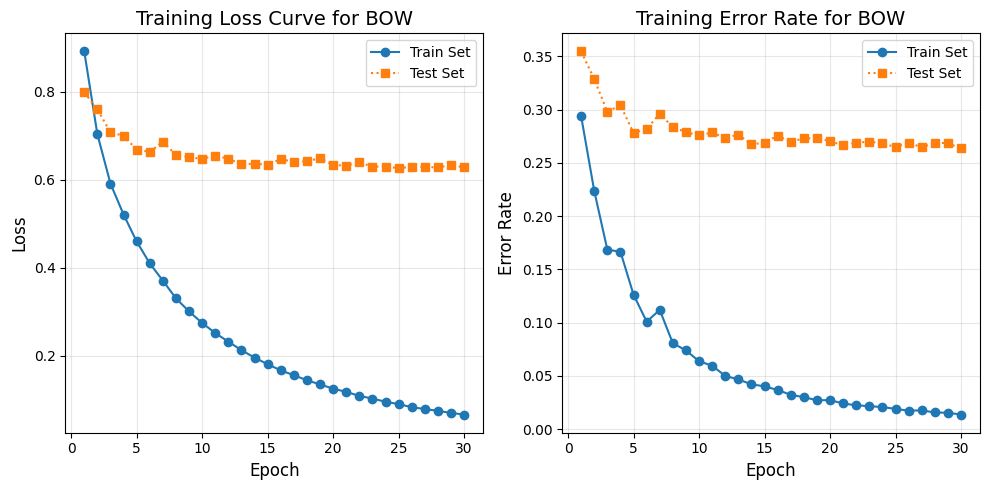

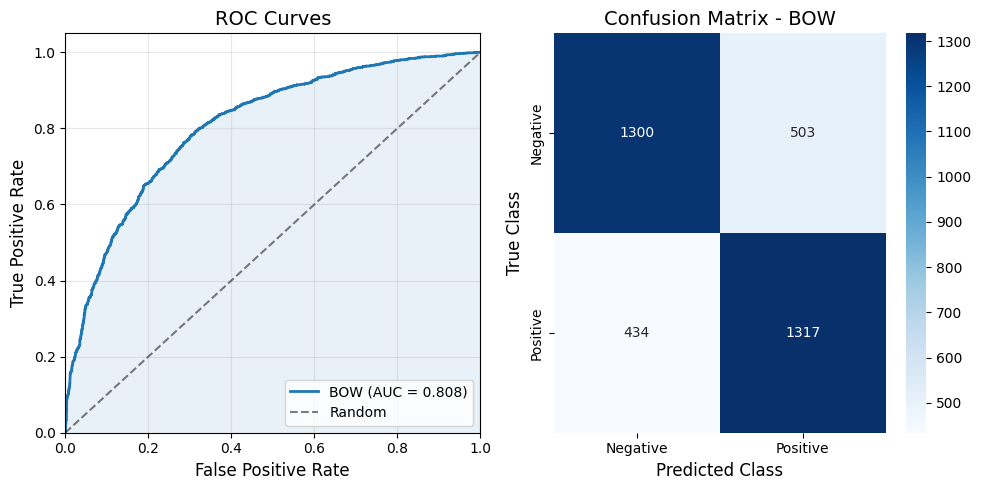

In [13]:
results['BOW'] = TestModel(extractFeatures_BOW, 30, 0.01)


Evaluation Results on Test Set for Ngram
Accuracy:  0.6705 (67.05%)
F1 Score:  0.6741
AUC:       0.7378


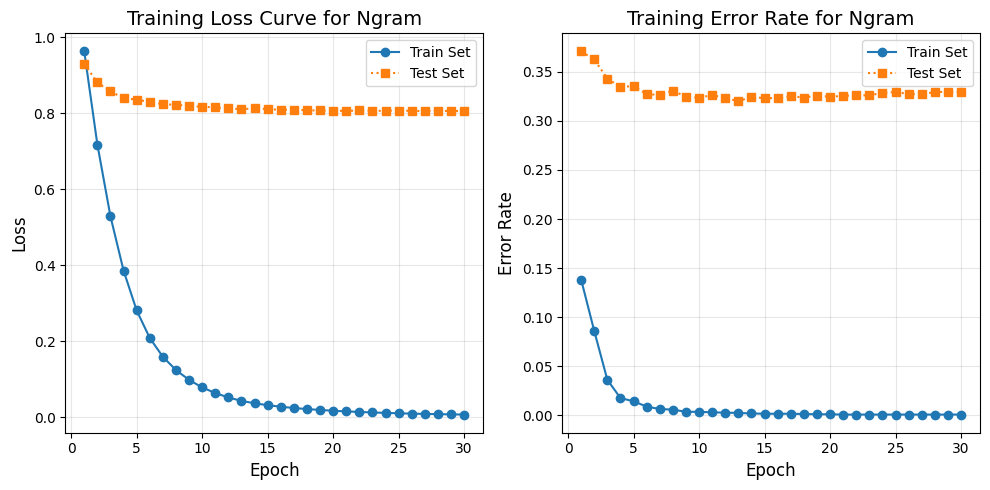

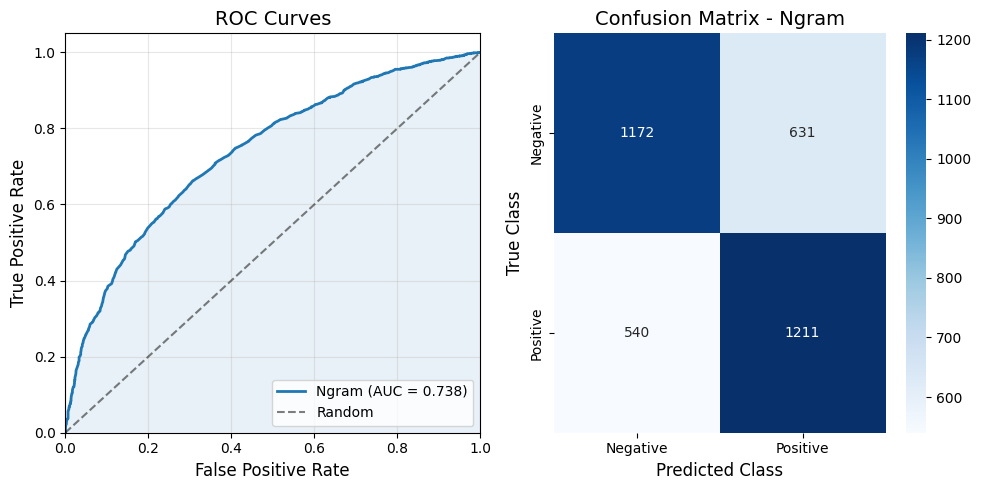

In [14]:
results['N-gram'] = TestModel(extractFeatures_Ngram, 30, 0.01)

In [15]:
class TFIDFVectorizer:
    """TF-IDF 特征提取器"""
    
    def __init__(self):
        self.doc_freq = collections.defaultdict(int)  # 文档频率
        self.num_docs = 0
        self.idf = {}
    
    def fit(self, documents):
        """计算 IDF"""
        self.num_docs = len(documents)
        
        # 计算文档频率
        for doc in documents:
            words = set(doc.split())  # 使用 set 去重
            for word in words:
                self.doc_freq[word] += 1
        
        # 计算 IDF
        for word, freq in self.doc_freq.items():
            self.idf[word] = math.log(self.num_docs / (1 + freq))
        
        return self
    
    def transform(self, text):
        """
        将文本转换为 TF-IDF 特征
        """
        words = text.split()
        word_count = len(words)
        
        if word_count == 0:
            return {}
        
        # 计算 TF
        tf = collections.defaultdict(float)
        for word in words:
            tf[word] += 1.0
        
        # 计算 TF-IDF
        features = {}
        for word, term_freq in tf.items():
            tf_value = term_freq / word_count  # 词频
            idf_value = self.idf.get(word, math.log(self.num_docs))  # IDF
            features[word] = tf_value * idf_value
        
        return features
    
    def fit_transform(self, documents):
        """拟合并转换"""
        self.fit(documents)
        return [self.transform(doc) for doc in documents]

train_texts = [x for x, y in trainExamples]
tfidf = TFIDFVectorizer()
tfidf.fit(train_texts)

# 在训练中使用
def extractFeatures_TFIDF(x):
    return tfidf.transform(x)


Evaluation Results on Test Set for TFIDF
Accuracy:  0.7434 (74.34%)
F1 Score:  0.7396
AUC:       0.8213


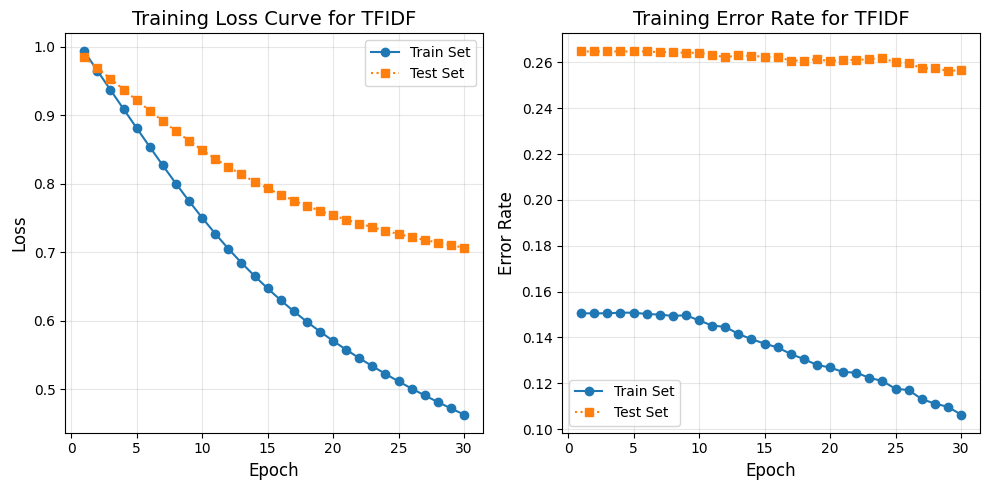

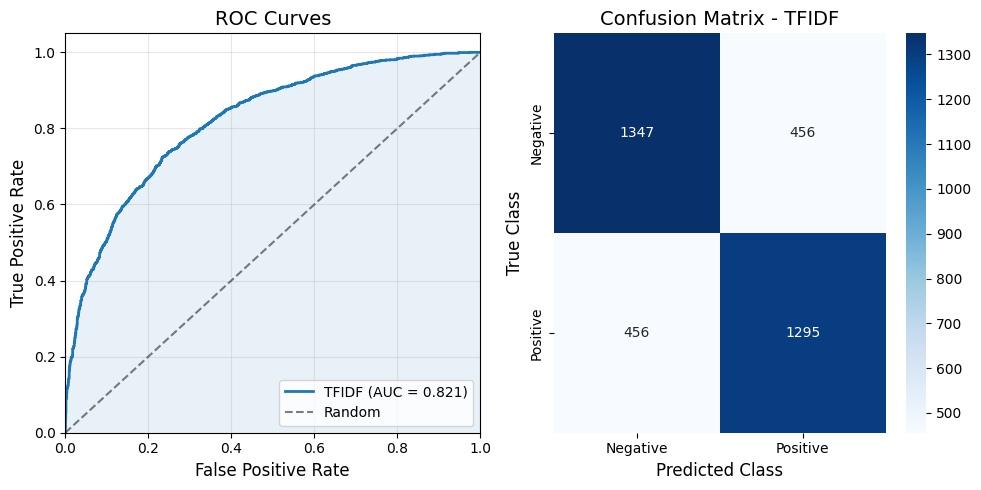

In [16]:
results['TF-IDF'] = TestModel(extractFeatures_TFIDF, 30, 0.01)

#### 词向量模型
* Word2Vec
* Doc2Vec

##### Word2Vec

文本特征提取函数 **extractFeatures_Word2Vec** 已在前文定义，词向量被转换为字典格式返回。

可以直接使用之前定义的训练和测试代码。


Evaluation Results on Test Set for Word2Vec
Accuracy:  0.7290 (72.90%)
F1 Score:  0.7133
AUC:       0.8083


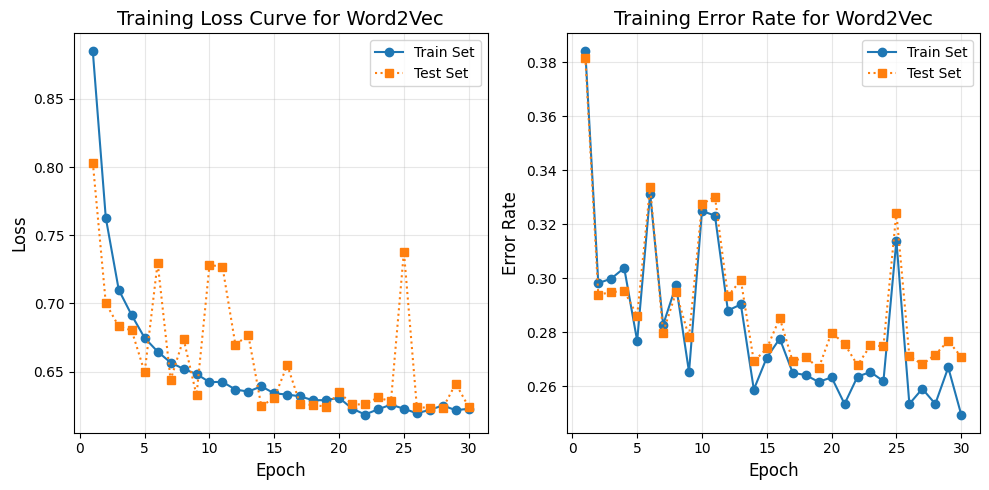

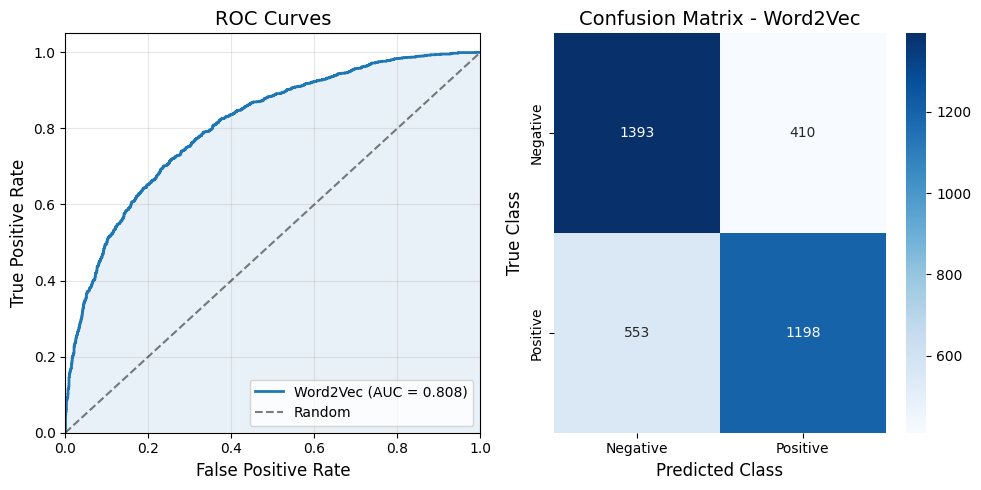

In [18]:
results['Word2Vec'] = TestModel(extractFeatures_Word2Vec, 30, 0.01)

##### Doc2Vec

In [19]:
# trainExamples = readExamples('data/data_rt.train')
# testExamples = readExamples('data/data_rt.test')
# results = {}

# 数据预处理（将文本和标签分开）
train_texts = [x for x, y in trainExamples]
train_labels = [y for x, y in trainExamples]
test_texts = [x for x, y in testExamples]
test_labels = [y for x, y in testExamples]

In [20]:
from gensim.models.doc2vec import TaggedDocument
from gensim.models import Doc2Vec
import numpy as np
import multiprocessing

def train_doc2vec(train_texts):
    """
    训练Doc2Vec模型
    
    Args:
        train_texts: 训练集文本列表
    
    Returns:
        model: 训练好的Doc2Vec模型
    """
    # ========== 核心参数配置 ==========
    vector_size = 100
    epochs = 300   # 足够多的轮次
    window = 3     # 更关注局部信息
    min_count = 1  # 保留所有词
    alpha = 0.025
    min_alpha = 0.001
    negative = 5
    sample = 1e-5
    
    # 将原始文本转换为TaggedDocument格式
    tagged_docs = [TaggedDocument(words=text.split(), tags=[str(i)]) 
                   for i, text in enumerate(train_texts)]
    
    # ========== 训练模型 ==========
    
    # 模型1: PV-DM
    print("\n1. 训练PV-DM模型...")
    model_dm = Doc2Vec(
        vector_size=vector_size,
        window=window,
        min_count=min_count,
        workers=multiprocessing.cpu_count(),
        epochs=epochs,
        dm=1,
        alpha=alpha,
        min_alpha=min_alpha,
        negative=negative,
        sample=sample, 
        hs=0,
        dm_mean=1,
        dm_concat=0,
        dbow_words=0
    ) 
    
    model_dm.build_vocab(tagged_docs)
    print(f"词汇表大小: {len(model_dm.wv.key_to_index)}")
    
    model_dm.train(tagged_docs,
                   total_examples=model_dm.corpus_count,
                   epochs=model_dm.epochs)
    
    # 模型2: PV-DBOW
    print("\n2. 训练PV-DBOW模型...")
    model_dbow = Doc2Vec(
        vector_size=vector_size,
        window=window,
        min_count=min_count,
        workers=multiprocessing.cpu_count(),
        epochs=epochs,
        dm=0,
        alpha=alpha,
        min_alpha=min_alpha,
        negative=negative,
        sample=sample,
        hs=0
    )
    
    model_dbow.build_vocab(tagged_docs)
    print(f"词汇表大小: {len(model_dbow.wv.key_to_index)}")
    model_dbow.train(tagged_docs,
                     total_examples=model_dbow.corpus_count,
                     epochs=model_dbow.epochs)

    # 训练集向量
    train_vecs_dm = np.array([model_dm.dv[str(i)] for i in range(len(tagged_docs))])
    train_vecs_dbow = np.array([model_dbow.dv[str(i)] for i in range(len(tagged_docs))])
   
    return model_dm, model_dbow, train_vecs_dm, train_vecs_dbow

def get_doc2vec(test_texts, model):
    test_vectors = []
    for text in test_texts:
        # 注意：infer_vector 输入的是分词后的词列表，且不会更新模型本身
        vector = model.infer_vector(text.split(), epochs=50, alpha=0.025)
        test_vectors.append(vector)
    return np.array(test_vectors)


In [21]:
model_dm, model_dbow, train_vecs_dm, train_vecs_dbow = train_doc2vec(train_texts)

test_vecs_dm = get_doc2vec(test_texts, model_dm)
test_vecs_dbow = get_doc2vec(test_texts, model_dbow)

train_vecs = np.hstack([train_vecs_dm, train_vecs_dbow])
test_vecs = np.hstack([test_vecs_dm, test_vecs_dbow])



1. 训练PV-DM模型...
词汇表大小: 11622

2. 训练PV-DBOW模型...
词汇表大小: 11622


**检验Doc2vec的训练效果，以确保后续分类学习的有效性:**

In [22]:
def check_doc2vec_quality(model, words):
    """
    检查Doc2vec是否学到了语义
    """
    print("检查词向量质量：")
    for word in words:
        if word in model.wv:
            similar = model.wv.most_similar(word, topn=3)
            print(f"{word}: {similar}")
    
    # 检查文档向量
    print("\n检查文档向量差异：")
    pos_vec = model.dv['0']  # 第一个正样本
    neg_vec = model.dv[str(len(train_texts)-1)]  # 最后一个负样本
    distance = np.linalg.norm(pos_vec - neg_vec)
    print(f"正负样本向量距离: {distance:.4f}")

words="a truly wonderful tale combined with stunning animation .".split()
check_doc2vec_quality(model_dm, words)

检查词向量质量：
a: [('is', 0.6254715919494629), ('all', 0.6245139241218567), ('qutting', 0.6224842667579651)]
truly: [('convict', 0.7598699331283569), ('ribbing', 0.7028334736824036), ('miracle', 0.6924698948860168)]
wonderful: [('ghastly', 0.945351779460907), ('burnt', 0.8844490051269531), ('marathons', 0.8723097443580627)]
tale: [('rashomon-for-dipsticks', 0.8843948245048523), ('cautionary', 0.7882652878761292), ('wonderful', 0.7453699111938477)]
combined: [('1959', 0.8885942697525024), ('godzilla', 0.8755794167518616), ('raymond', 0.871979832649231)]
with: [('sparkles', 0.6604282259941101), ('impact', 0.6377744674682617), ('[roman', 0.6172711253166199)]
stunning: [('fusion', 0.8098486661911011), ('gai', 0.8093330264091492), ('senegalese', 0.7948703169822693)]
animation: [('die-hard', 0.8510520458221436), ('japanese', 0.7568451166152954), ('enthusiasts', 0.7517481446266174)]
.: [('recommend', 0.7044702768325806), ('ending', 0.6938096284866333), ('showgirls</>', 0.6801328063011169)]

检查文档向量差

**为了使用之前定义的Linge Loss训练器，需要将稠密向量转换成字典格式：**

In [23]:
def vec_to_dict(X, y):
    """
    将稠密向量适配成字典格式
    X: numpy数组，shape=(n_samples, dim)
    """
    examples = []
    for i in range(len(X)):
        # 将每个向量转为字典：{'dim_0': val0, 'dim_1': val1, ...}
        features = {f'dim_{j}': float(X[i][j]) for j in range(len(X[i]))}
        examples.append((features, y[i]))
    return examples

trainExamples_dict = vec_to_dict(train_vecs, train_labels)
testExamples_dict = vec_to_dict(test_vecs, test_labels)


Evaluation Results on Test Set for Doc2Vec
Accuracy:  0.6497 (64.97%)
F1 Score:  0.6665
AUC:       0.6946


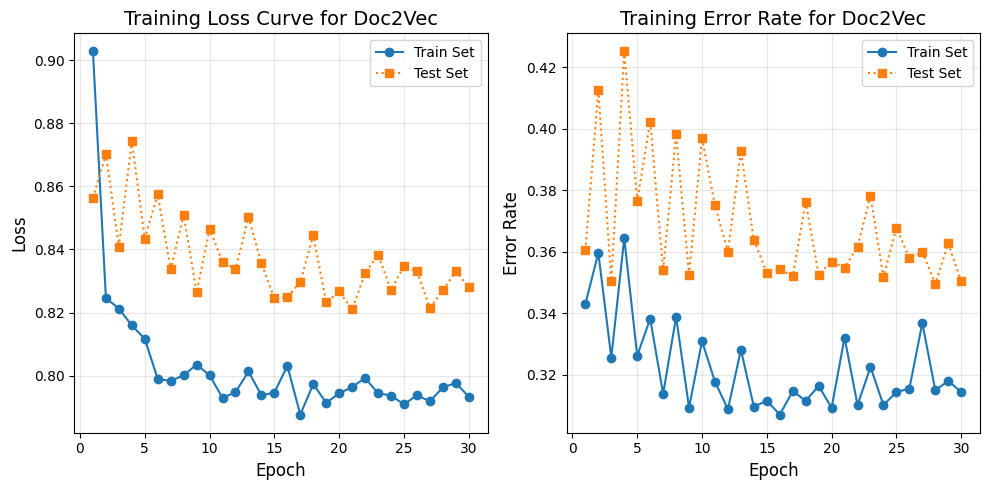

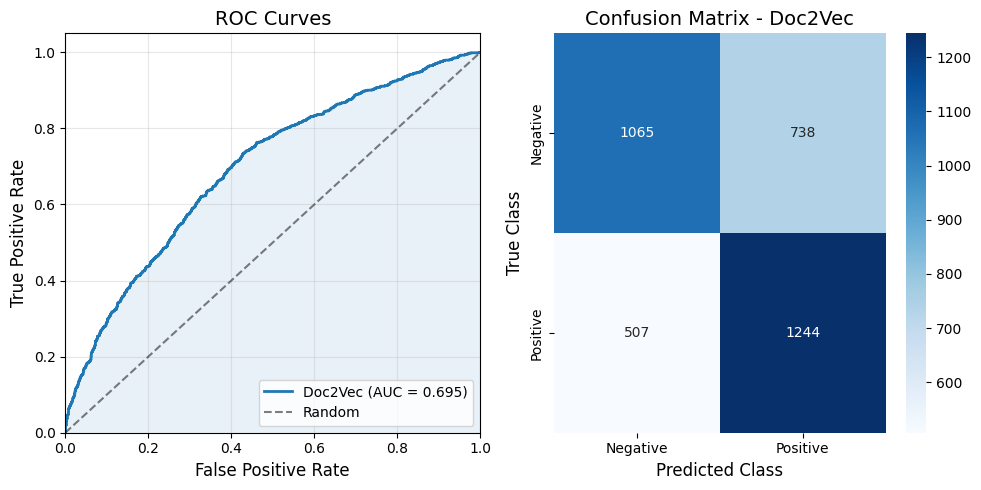

In [27]:
def extractFeatures_Doc2Vec(x_dict):
    """
    Doc2Vec整个文档特征提取已经完成
    """
    return x_dict

results['Doc2Vec'] = TestModel(extractFeatures_Doc2Vec, 30, 0.01, trainExamples_dict, testExamples_dict)

直接使用Doc2Vec提取的句子向量，用向量计算重写学习和训练代码（对比验证一下上面的结果）

In [28]:
import numpy as np
import random
from collections import defaultdict

def learnPredictor_vector(train_vectors, train_labels, 
                          test_vectors, test_labels,
                          numIters, eta):
    """
    适用于稠密向量的Hinge Loss训练器
    
    Args:
        train_vectors: numpy数组, shape=(n_train, dim)
        train_labels: numpy数组, shape=(n_train,)
        test_vectors: numpy数组, shape=(n_test, dim)
        test_labels: numpy数组, shape=(n_test,)
        numIters: 迭代轮数
        eta: 学习率
    """
    # 初始化权重为零向量
    dim = train_vectors.shape[1]
    weights = np.zeros(dim)
    
    train_losses = []
    test_losses = []
    train_errors = []
    test_errors = []
    
    # 组合成样本列表便于打乱
    train_samples = list(zip(train_vectors, train_labels))
    
    for i in range(1, numIters + 1):
        # 随机打乱
        random.shuffle(train_samples)
        
        total_loss = 0.0
        
        # 训练
        for x, y in train_samples:
            # 计算得分: w·x
            score = np.dot(weights, x)
            
            margin = y * score
            if margin < 1:
                # 权重更新: w = w + eta * y * x
                weights += eta * y * x
                total_loss += 1 - margin
        
        avg_train_loss = total_loss / len(train_samples)
        train_losses.append(avg_train_loss)
        
        # 测试损失
        test_total_loss = 0.0
        for x, y in zip(test_vectors, test_labels):
            score = np.dot(weights, x)
            margin = y * score
            test_total_loss += max(0, 1 - margin)
        
        avg_test_loss = test_total_loss / len(test_vectors)
        test_losses.append(avg_test_loss)
        
        train_pred = np.sign(np.dot(train_vectors, weights))
        train_error = np.mean(train_pred != train_labels)
        train_errors.append(train_error)
            
        test_pred = np.sign(np.dot(test_vectors, weights))
        test_error = np.mean(test_pred != test_labels)
        test_errors.append(test_error)
        
        # 定期输出
        if i % 10 == 0 or i == 1:   
            print(f"Iter {i:3d}: train loss={avg_train_loss:.4f}, test loss={avg_test_loss:.4f}, "
                  f"train error={train_error:.4f}, test error={test_error:.4f}")
    
    return weights, train_losses, test_losses, train_errors, test_errors

In [29]:
def evaluate_model_vector(weights, test_vectors, test_labels, model_name='Doc2Vec'):
    
    # 预测类别（阈值=0）
    scores = np.dot(test_vectors, weights)
    test_pred = np.sign(scores)
    
    # 保存模型名称和各项指标
    results = {}
    results['model'] = model_name
    
    # 1. 准确率
    accuracy = np.mean(test_pred == test_labels)
    results['accuracy'] = accuracy
    
    # 2. 将标签转换为0/1（用于F1和ROC）
    y_true_binary = np.where(test_labels == 1, 1, 0)
    y_pred_binary = np.where(test_pred == 1, 1, 0)
    
    # 3. F1分数
    results['f1'] = f1_score(y_true_binary, y_pred_binary)
    
    # 4. 混淆矩阵
    cm = confusion_matrix(y_true_binary, y_pred_binary)
    results['confusion_matrix'] = cm
    
    # 5. ROC曲线和AUC
    # 将得分转换为概率（通过sigmoid）
    y_score = 1 / (1 + np.exp(-scores))
    fpr, tpr, thresholds = roc_curve(y_true_binary, y_score)
    results['roc_auc'] = auc(fpr, tpr)
    results['fpr'] = fpr
    results['tpr'] = tpr
    results['roc_thresholds'] = thresholds
    
    return results, y_true_binary, y_score


In [30]:
def TestModel_vector(train_vectors, train_labels, test_vectors, test_labels, numIters, eta):
    # 模型训练
    weights, train_losses, test_losses, train_errors, test_errors = learnPredictor_vector(
        train_vectors, train_labels, test_vectors, test_labels, numIters, eta)
    
    # 绘制训练过程中的损失函数变化曲线
    plot_losses_and_errors(train_losses, test_losses, train_errors, test_errors, 'Doc2Vec')

    # 在训练集上计算评价指标
    results, y_true_binary, y_score = evaluate_model_vector(weights, test_vectors, test_labels)

    # 打印指标
    print_evaluation_results(results)

    # 绘制ROC和混淆矩阵热力图
    plot_roc_cm(results)
    
    return results

Iter   1: train loss=0.9012, test loss=0.8518, train error=0.3354, test error=0.3562
Iter  10: train loss=0.7971, test loss=0.8354, train error=0.3140, test error=0.3557
Iter  20: train loss=0.7971, test loss=0.8275, train error=0.3495, test error=0.3683
Iter  30: train loss=0.7960, test loss=0.8143, train error=0.3154, test error=0.3517

Evaluation Results on Test Set for Doc2Vec
Accuracy:  0.6483 (64.83%)
F1 Score:  0.6514
AUC:       0.6979


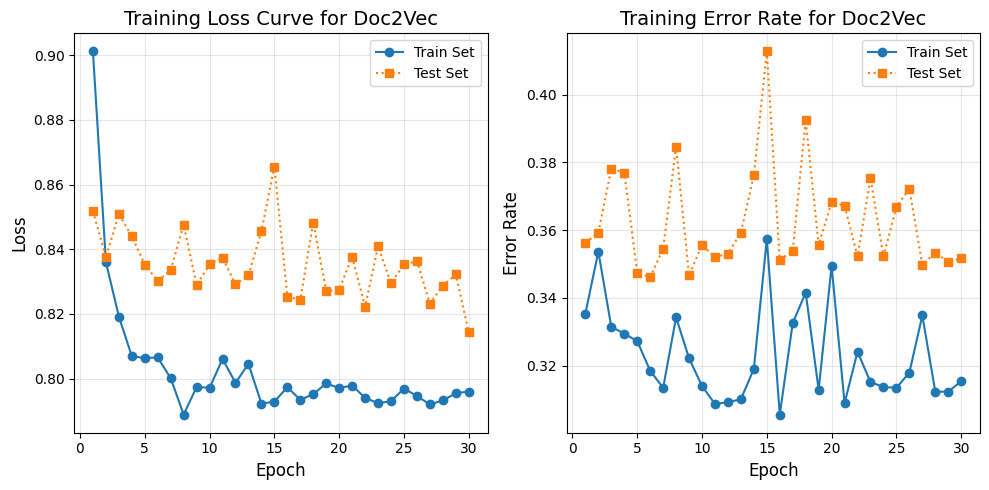

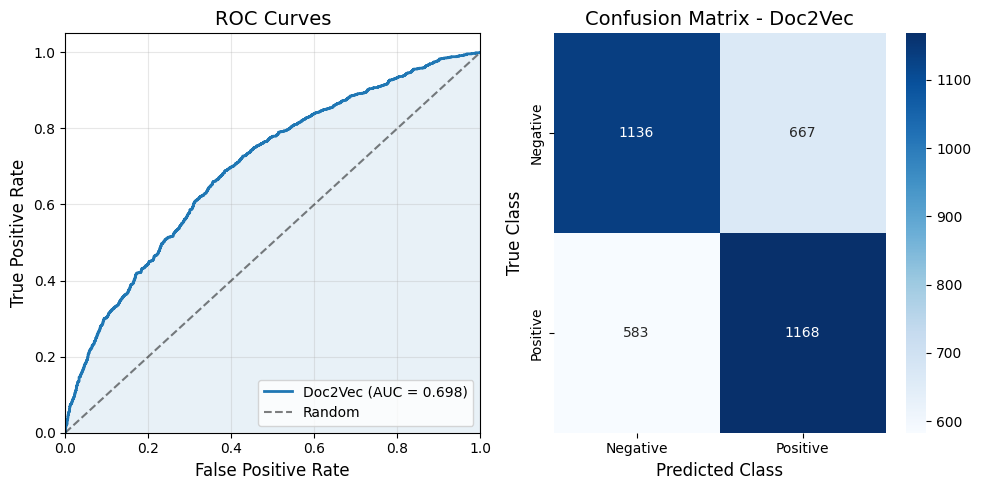

In [31]:
train_labels = np.array(train_labels)
test_labels = np.array(test_labels)

results['Doc2Vec'] = TestModel_vector(train_vecs, train_labels, test_vecs, test_labels, 30, 0.01)

### SVM

In [71]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def train_svm_classifier(X_train, y_train, X_test, y_test, featureExtractorName):
    """
    训练SVM分类器
    使用线性核的SVM
    """
    svm_pipeline = make_pipeline(
        StandardScaler(),  # 标准化：使每个维度均值为0，方差为1
        SVC(kernel='linear', class_weight='balanced', max_iter=5000, probability=True)
    )
    
    # 定义要搜索的参数网格
    param_grid = {'svc__C': [0.001, 0.005, 0.01, 0.1, 1, 10]}

    # 创建 GridSearchCV 对象
    grid_search = GridSearchCV(svm_pipeline, param_grid, cv=5, scoring='f1')

    # 在训练数据上进行搜索
    grid_search.fit(X_train, y_train)

    print(f"最佳参数: {grid_search.best_params_}")
    print(f"最佳交叉验证 F1: {grid_search.best_score_:.4f}")

    # 使用最佳模型预测
    best_svm = grid_search.best_estimator_
    y_pred = best_svm.predict(X_test)
    y_prob = best_svm.predict_proba(X_test)[:, 1]  # 用于AUC
    
    # 评估
    results = {}
    results['accuracy'] = accuracy_score(y_test, y_pred)
    results['f1'] = f1_score(y_test, y_pred)

    results['confusion_matrix'] = confusion_matrix(y_test, y_pred)

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    results['roc_auc'] = auc(fpr, tpr)
    results['fpr'] = fpr
    results['tpr'] = tpr
    results['roc_thresholds'] = thresholds

    results['model'] = featureExtractorName + '+SVM'
    
    return svm, results, y_pred, y_prob

#### BOW + SVM

In [42]:
from sklearn.feature_extraction import DictVectorizer

def prepare_data(featureExtractor, trainExamples, testExamples):
    """
    将文本按照特征提取方式先转化成字典
    再转换成SVM能处理的矩阵格式
    """
    features_train, y_train = get_dict_features(featureExtractor, trainExamples)
    features_test, y_test = get_dict_features(featureExtractor, testExamples)

    # 使用 DictVectorizer 将字典列表转换为稀疏矩阵
    vectorizer = DictVectorizer(sparse=True)  # sparse=True 可以节省大量内存
    X_train = vectorizer.fit_transform(features_train)  # 在训练集上拟合并转换
    X_test = vectorizer.transform(features_test)        # 在测试集上只转换，不拟合

    featureExtractor_name = featureExtractor.__name__.split('_')[-1]
   
    return X_train, y_train, X_test, y_test, featureExtractor_name
 
    
def get_dict_features(featureExtractor, examples):
    features = []
    labels = []
    for x, y in examples:
        feature = featureExtractor(x)
        features.append(feature)
        labels.append(y)
    return features, labels
  

In [48]:
X_train, y_train, X_test, y_test, featureExtractor_name = prepare_data(extractFeatures_BOW, trainExamples, testExamples)

# 模型训练并计算评价指标
svm, results['BOW+SVM'], y_pred, y_prob = train_svm_classifier(X_train, y_train, X_test, y_test, featureExtractor_name)

# 打印指标
print_evaluation_results(results['BOW+SVM'])

最佳参数: {'C': 0.1}
最佳交叉验证 F1: 0.7106

Evaluation Results on Test Set for BOW+SVM
Accuracy:  0.7369 (73.69%)
F1 Score:  0.7352
AUC:       0.8052


#### N-gram + SVM

In [49]:
X_train, y_train, X_test, y_test, featureExtractor_name = prepare_data(extractFeatures_Ngram, trainExamples, testExamples)

# 模型训练并计算评价指标
svm, results['N-gram+SVM'], y_pred, y_prob = train_svm_classifier(X_train, y_train, X_test, y_test, featureExtractor_name)

# 打印指标
print_evaluation_results(results['N-gram+SVM'])

最佳参数: {'C': 0.1}
最佳交叉验证 F1: 0.6654

Evaluation Results on Test Set for Ngram+SVM
Accuracy:  0.6761 (67.61%)
F1 Score:  0.6705
AUC:       0.7369


#### TF-IDF + SVM

In [50]:
X_train, y_train, X_test, y_test, featureExtractor_name = prepare_data(extractFeatures_TFIDF, trainExamples, testExamples)

# 模型训练并计算评价指标
svm, results['TF-IDF+SVM'], y_pred, y_prob = train_svm_classifier(X_train, y_train, X_test, y_test, featureExtractor_name)

# 打印指标
print_evaluation_results(results['TF-IDF+SVM'])

最佳参数: {'C': 1}
最佳交叉验证 F1: 0.7201

Evaluation Results on Test Set for TFIDF+SVM
Accuracy:  0.7428 (74.28%)
F1 Score:  0.7433
AUC:       0.8199


#### Word2Vec + SVM

In [72]:
X_train = [extractFeatures_Word2Vec_2(x) for x, y in testExamples]
y_train = [y for x, y in trainExamples]
X_test = [extractFeatures_Word2Vec_2(x) for x, y in testExamples]
y_test = [y for x, y in trainExamples]

# 模型训练并计算评价指标
svm, results['Word2Vec+SVM'], y_pred, y_prob = train_svm_classifier(X_train, y_train, X_test, y_test, 'Word2Vec')

# 打印指标
print_evaluation_results(results['Word2Vec+SVM'])

C:\Users\gaott\.conda\envs\torch1.10+cu102\lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\gaott\.conda\envs\torch1.10+cu102\lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\gaott\.conda\envs\torch1.10+cu102\lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\gaott\.conda\envs\torch1.10+cu102\lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
C:\Users\gaott\.conda\envs\torch1.10+cu102\lib\site-

最佳参数: {'svc__C': 1}
最佳交叉验证 F1: 0.6249

Evaluation Results on Test Set for Word2Vec+SVM
Accuracy:  0.5011 (50.11%)
F1 Score:  0.6268
AUC:       0.4978


#### Doc2Vec + SVM

In [64]:
# # 数据预处理（将文本和标签分开）
# train_texts = [x for x, y in trainExamples]
# train_labels = [y for x, y in trainExamples]
# test_texts = [x for x, y in testExamples]
# test_labels = [y for x, y in testExamples]

# model_dm, model_dbow, train_vecs_dm, train_vecs_dbow = train_doc2vec(train_texts)

# test_vecs_dm = get_doc2vec(test_texts, model_dm)
# test_vecs_dbow = get_doc2vec(test_texts, model_dbow)

# train_vecs = np.hstack([train_vecs_dm, train_vecs_dbow])
# test_vecs = np.hstack([test_vecs_dm, test_vecs_dbow])

# train_labels = np.array(train_labels)
# test_labels = np.array(test_labels)

# 模型训练并计算评价指标
svm, results['Doc2Vec+SVM'], y_pred, y_prob = train_svm_classifier(train_vecs, train_labels, test_vecs, test_labels, 'Doc2Vec')

# 打印指标
print_evaluation_results(results['Doc2Vec+SVM'])

最佳参数: {'C': 0.001}
最佳交叉验证 F1: 0.6561

Evaluation Results on Test Set for Doc2Vec+SVM
Accuracy:  0.5101 (51.01%)
F1 Score:  0.6645
AUC:       0.6796


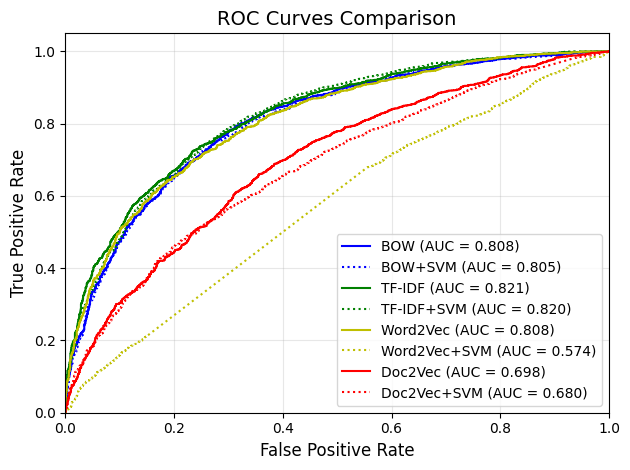

In [66]:
def compare_roc_curves(results):
    """
    绘制ROC曲线对比图
    """
    
    # 绘制ROC曲线
    plt.plot(results['BOW']['fpr'], results['BOW']['tpr'], 'b', 
             label=f"{'BOW'} (AUC = {results['BOW']['roc_auc']:.3f})")
    plt.plot(results['BOW+SVM']['fpr'], results['BOW+SVM']['tpr'], 'b:', 
             label=f"{'BOW+SVM'} (AUC = {results['BOW+SVM']['roc_auc']:.3f})")
    plt.plot(results['TF-IDF']['fpr'], results['TF-IDF']['tpr'], 'g', 
             label=f"{'TF-IDF'} (AUC = {results['TF-IDF']['roc_auc']:.3f})")
    plt.plot(results['TF-IDF+SVM']['fpr'], results['TF-IDF+SVM']['tpr'], 'g:', 
             label=f"{'TF-IDF+SVM'} (AUC = {results['TF-IDF+SVM']['roc_auc']:.3f})")
    plt.plot(results['Word2Vec']['fpr'], results['Word2Vec']['tpr'], 'y', 
             label=f"{'Word2Vec'} (AUC = {results['Word2Vec']['roc_auc']:.3f})")
    plt.plot(results['Word2Vec+SVM']['fpr'], results['Word2Vec+SVM']['tpr'], 'y:', 
             label=f"{'Word2Vec+SVM'} (AUC = {results['Word2Vec+SVM']['roc_auc']:.3f})")
    plt.plot(results['Doc2Vec']['fpr'], results['Doc2Vec']['tpr'], 'r', 
             label=f"{'Doc2Vec'} (AUC = {results['Doc2Vec']['roc_auc']:.3f})")
    plt.plot(results['Doc2Vec+SVM']['fpr'], results['Doc2Vec+SVM']['tpr'], 'r:', 
             label=f"{'Doc2Vec+SVM'} (AUC = {results['Doc2Vec+SVM']['roc_auc']:.3f})")
    
    # 绘制对角线（随机分类器）
    # plt.plot([0, 1], [0, 1], 'k--', label='Random', alpha=0.5)
    
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('ROC Curves Comparison', fontsize=14)
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

compare_roc_curves(results)

### BERT的[CLS]向量

BERT [CLS] + SVM 情感分类
使用设备: cuda


Some weights of the model checkpoint at ./bert-base-uncased-local were not used when initializing BertModel: ['cls.predictions.transform.LayerNorm.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.dense.bias', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.seq_relationship.weight', 'cls.predictions.decoder.weight', 'cls.predictions.transform.dense.weight']
- This IS expected if you are initializing BertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


向量维度: 768

编码训练集...
训练集向量形状: (3554, 768)
编码测试集...
测试集向量形状: (3554, 768)

训练SVM分类器...

Evaluation Results on Test Set for BERT+SVM
Accuracy:  0.7932 (79.32%)
F1 Score:  0.7879
AUC:       0.8726


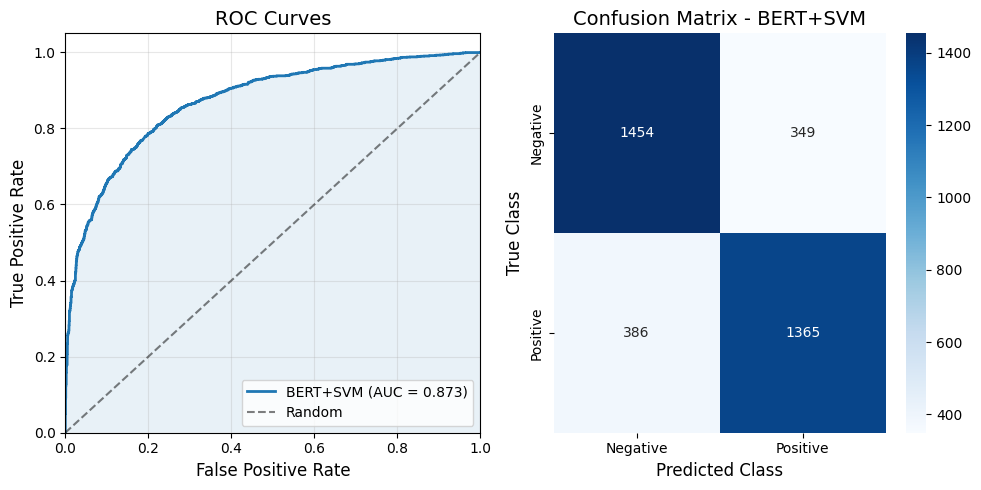

In [76]:
import torch
from transformers import BertTokenizer, BertModel
import numpy as np
from sklearn.svm import SVC
from sklearn.metrics import f1_score
import warnings
warnings.filterwarnings('ignore')

BERT_PATH = './bert-base-uncased-local'

class BERTVectorizer:
    """
    使用BERT的[CLS]向量作为句子表示
    """
    def __init__(self, bert_path, device=None, max_length=128):
        """
        Args:
            model_name: BERT模型名称
            device: 'cuda'或'cpu'
            max_length: 最大序列长度
        """
        self.device = device if device else ('cuda' if torch.cuda.is_available() else 'cpu')
        print(f"使用设备: {self.device}")
        
        # 加载tokenizer和模型
        self.tokenizer = BertTokenizer.from_pretrained(bert_path)
        self.model = BertModel.from_pretrained(bert_path)
        self.model.to(self.device)
        self.model.eval()  # 评估模式
        self.max_length = max_length
        
        # BERT-base的隐藏层维度是768
        self.vector_size = 768
        
    def encode(self, texts, batch_size=32):
        """
        将文本列表转换为[CLS]向量
        
        Args:
            texts: 文本列表
            batch_size: 批处理大小
        
        Returns:
            numpy数组，shape=(len(texts), 768)
        """
        all_embeddings = []
        
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i+batch_size]
            
            # 分词
            inputs = self.tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=self.max_length,
                return_tensors='pt'
            ).to(self.device)
            
            # 获取BERT输出
            with torch.no_grad():
                outputs = self.model(**inputs)
                # 提取[CLS]向量 (outputs.last_hidden_state[:, 0, :])
                cls_embeddings = outputs.last_hidden_state[:, 0, :].cpu().numpy()
                all_embeddings.append(cls_embeddings)
        
        return np.vstack(all_embeddings)

# 使用示例
def bert_cls_example(train_texts, train_labels, test_texts, test_labels):
    """
    完整的BERT [CLS] + SVM流程
    """
    print("="*60)
    print("BERT [CLS] + SVM 情感分类")
    print("="*60)
    
    # 1. 初始化BERT向量器
    vectorizer = BERTVectorizer(bert_path=BERT_PATH)
    print(f"向量维度: {vectorizer.vector_size}")
    
    # 2. 编码训练集和测试集
    print("\n编码训练集...")
    X_train = vectorizer.encode(train_texts)
    print(f"训练集向量形状: {X_train.shape}")
    
    print("编码测试集...")
    X_test = vectorizer.encode(test_texts)
    print(f"测试集向量形状: {X_test.shape}")
    
    # 3. 训练SVM
    print("\n训练SVM分类器...")
    svm = SVC(kernel='linear', class_weight='balanced', C=1.0, probability=True)
    svm.fit(X_train, train_labels)
    
    # 4. 预测
    y_pred = svm.predict(X_test)
    y_prob = svm.predict_proba(X_test)[:, 1]  # 用于AUC
    
    evaluations = {}
    
    evaluations['accuracy'] = accuracy_score(test_labels, y_pred)
    evaluations['f1'] = f1_score(test_labels, y_pred, pos_label=1)
    evaluations['confusion_matrix'] = confusion_matrix(test_labels, y_pred)
    fpr, tpr, thresholds = roc_curve(test_labels, y_prob)
    evaluations['roc_auc'] = auc(fpr, tpr)
    evaluations['fpr'] = fpr
    evaluations['tpr'] = tpr
    evaluations['roc_thresholds'] = thresholds

    evaluations['model'] = 'BERT+SVM'
    
    return vectorizer, svm, evaluations

vectorizer, svm, results['BERT+SVM'] = bert_cls_example(train_texts, train_labels, test_texts, test_labels)
print_evaluation_results(results['BERT+SVM'])
plot_roc_cm(results['BERT+SVM'])

In [80]:
import pandas as pd

df = pd.DataFrame(results)

pd.DataFrame(results)

,BOW,N-gram,TF-IDF,Word2Vec,Doc2Vec,BOW+SVM,N-gram+SVM,TF-IDF+SVM,Word2Vec+SVM,Doc2Vec+SVM,BERT+SVM
model,BOW,Ngram,TFIDF,Word2Vec,Doc2Vec,BOW+SVM,Ngram+SVM,TFIDF+SVM,Word2Vec+SVM,Doc2Vec+SVM,BERT+SVM
accuracy,0.736353,0.670512,0.743388,0.729038,0.648284,0.736916,0.67614,0.742825,0.501125,0.510129,0.793191
f1,0.737609,0.674089,0.739577,0.713308,0.651422,0.735202,0.670484,0.743258,0.626815,0.664483,0.787879
confusion_matrix,"[[1300, 503], [434, 1317]]","[[1172, 631], [540, 1211]]","[[1347, 456], [456, 1295]]","[[1393, 410], [553, 1198]]","[[1136, 667], [583, 1168]]","[[1321, 482], [453, 1298]]","[[1232, 571], [580, 1171]]","[[1317, 486], [428, 1323]]","[[292, 1492], [281, 1489]]","[[89, 1714], [27, 1724]]","[[1454, 349], [386, 1365]]"
roc_auc,0.808003,0.737817,0.821301,0.808318,0.69791,0.805187,0.736886,0.819861,0.497771,0.679579,0.872555
fpr,"[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.9035874439461884, 0.9035874439461884, ...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055...","[0.0, 0.0, 0.0, 0.0005546311702717693, 0.00055..."
tpr,"[0.0, 0.0005711022272986865, 0.005711022272986...","[0.0, 0.0005711022272986865, 0.001713306681896...","[0.0, 0.0005711022272986865, 0.014848657909765...","[0.0, 0.0005711022272986865, 0.012564249000571...","[0.0, 0.0005711022272986865, 0.003997715591090...","[0.0, 0.0005711022272986865, 0.011993146773272...","[0.0, 0.0005711022272986865, 0.004568817818389...","[0.0, 0.0005711022272986865, 0.019417475728155...","[0.0, 0.8988700564971751, 0.8994350282485876, ...","[0.0, 0.0005711022272986865, 0.007995431182181...","[0.0, 0.0005711022272986865, 0.049685893774985..."
roc_thresholds,"[inf, 0.9938185391083887, 0.9774673605435525, ...","[inf, 0.93276754941215, 0.8859476187202091, 0....","[inf, 0.9468857525558829, 0.8460115053205207, ...","[inf, 0.9986031181850026, 0.9813807177158791, ...","[inf, 0.9425964411707597, 0.9088779133454287, ...","[inf, 0.9999811328811591, 0.9661265734159047, ...","[inf, 0.9931167856411104, 0.9767152935737153, ...","[inf, 0.9999995655501008, 0.9802362847009709, ...","[inf, 0.5, 0.49499694490514506, 0.494993076398...","[inf, 0.6224930074206756, 0.5940786820820522, ...","[inf, 0.999999109745723, 0.9765396955246224, 0..."


In [86]:
df_filter = df.loc[['accuracy','f1','roc_auc'], ['BOW','N-gram','TF-IDF','Word2Vec','Doc2Vec','BERT+SVM']].apply(pd.to_numeric)
df_filter.round(4)

,BOW,N-gram,TF-IDF,Word2Vec,Doc2Vec,BERT+SVM
accuracy,0.7364,0.6705,0.7434,0.7290,0.6483,0.7932
f1,0.7376,0.6741,0.7396,0.7133,0.6514,0.7879
roc_auc,0.8080,0.7378,0.8213,0.8083,0.6979,0.8726
